In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sacc
from cobaya.model import get_model
import baccoemu
import pyccl as ccl
from cl_like_free import Likelihood
mpk = baccoemu.Matter_powerspectrum(nonlinear_model_name='Arico2023')

Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.


In [103]:
fits_file = '/home/mzennaro/CosmoCodes/Notebooks/TestClLike/data/cls_cov_GSSC_20260313.fits'
bins = [
    {'name': 'DESY3wl__0'},
    {'name': 'DESY3wl__1'},
    {'name': 'DESY3wl__2'},
    {'name': 'DESY3wl__3'},
]
twopoints = [
    {'bins': ['DESY3wl__0', 'DESY3wl__0']},
    {'bins': ['DESY3wl__0', 'DESY3wl__1']},
    {'bins': ['DESY3wl__0', 'DESY3wl__2']},
    {'bins': ['DESY3wl__0', 'DESY3wl__3']},
    {'bins': ['DESY3wl__1', 'DESY3wl__1']},
    {'bins': ['DESY3wl__1', 'DESY3wl__2']},
    {'bins': ['DESY3wl__1', 'DESY3wl__3']},
    {'bins': ['DESY3wl__2', 'DESY3wl__2']},
    {'bins': ['DESY3wl__2', 'DESY3wl__3']},
    {'bins': ['DESY3wl__3', 'DESY3wl__3']},
]
defaults = {
    'DESY3wl__0': {'lmin': 20, 'lmax': 8500},
    'DESY3wl__1': {'lmin': 20, 'lmax': 8500},
    'DESY3wl__2': {'lmin': 20, 'lmax': 8500},
    'DESY3wl__3': {'lmin': 20, 'lmax': 8500},
}
ia_parameters = {
    'ia_model': 'IADESY1_PerSurvey',
    'input_params_prefix': 'ia'

    # 'ia_model': 'IANone'
}
magnification_bias_parameters = {
    'use_magnification_bias': False,
    'input_params_prefix': 'mag'
}
nz_uncertainty_parameters = {
    'nz_model': 'NzShift',
    'input_params_prefix': 'nz'
}
shape_model_parameters = {
    'shape_model': 'ShapeMultiplicative',
    'input_params_prefix': 'shape'
}

print('Number of cross-correlations: ', len(twopoints))
print('')
sampling_params = {
    'Omega_cdm': 0.309909-0.0616739-0.06/93.14/0.686672**2,
    'Omega_b': 0.0616739,
    'h': 0.686672,
    # 'n_s': 1.04305,
    'n_s': 0.974135,
    'A_s': 2.12174e-9,
    'w0': -1.0,
    'wa': 0.0,
    'M_nu': 0.06,

    'ia_DESY3wl_A_IA': 0.139753,
    # 'ia_DESY3wl_eta_IA': 0.00534004,

    # 'ia_DESY3wl_A_IA': -1.0,
    'ia_DESY3wl_eta_IA': 0.0,

    'nz_DESY3wl__0_dz': 0.0,
    'nz_DESY3wl__1_dz': 0.0,
    'nz_DESY3wl__2_dz': 0.0,
    'nz_DESY3wl__3_dz': 0.0,

    'shape_DESY3wl__0_m': 0.0,
    'shape_DESY3wl__1_m': 0.0,
    'shape_DESY3wl__2_m': 0.0,
    'shape_DESY3wl__3_m': 0.0,

}

print('Number of sampling parameters: ', len(sampling_params))

myll = Likelihood(fits_file=fits_file, bins=bins, twopoints=twopoints, defaults=defaults, sample_type='convolve', bias_input_name='bias', use_baryons=False, ia_parameters=ia_parameters, magnification_bias_parameters=magnification_bias_parameters, nz_uncertainty_parameters=nz_uncertainty_parameters, shape_model_parameters=shape_model_parameters, debug=True)
theory_vector = myll.get_theory_perbin(sampling_params)

Number of cross-correlations:  10

Number of sampling parameters:  18
Loading l-bias lpt emulator...
L-bias lpt emulator loaded in memory.
Loading smeared bao emulator...
Smeared bao emulator loaded in memory.
Loading non-linear l-bias emulator...
Nonlinear l-bias emulator loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.
Initializing theory calculator in debug mode
WARNIG: in debug mode, NOT clearing cache for heft_calculator and mpk_calculator


In [104]:
fname = '/home/mzennaro/CosmoCodes/Notebooks/TestClLike/data/cls_cov_GSSC_20260313.fits'
s = sacc.Sacc.load_fits(fname)

In [105]:
paramfile = '../compare_cl_like_files/test_DES_minimise_lmax4500.yml'
model = get_model(paramfile)
pars = {}
# with open('../chains/test_DES_kmax4.0.minimum', 'r') as f:
with open('../compare_cl_like_files/test_DES_GSSC_lmax4500.minimum', 'r') as f:
    lines = f.readlines()
    for i in range(len(lines)):
        if (i > 2) & (i < 25):
            w = lines[i].split()
            pars[w[2]] = float(w[1])
pars['n_s'] = 0.974135
# pars['bias_DESY3wl_A_IA'] = -1.0
pars['limber_DESY3wl_eta_IA'] = 0.0
pars['bias_DESY3wl__0_m'] = 0.0
pars['bias_DESY3wl__1_m'] = 0.0
pars['bias_DESY3wl__2_m'] = 0.0
pars['bias_DESY3wl__3_m'] = 0.0
pars['limber_DESY3wl__0_dz'] = 0.0
pars['limber_DESY3wl__1_dz'] = 0.0
pars['limber_DESY3wl__2_dz'] = 0.0
pars['limber_DESY3wl__3_dz'] = 0.0
del pars['M_c']
del pars['eta']
del pars['beta']
del pars['M1_z0_cen']
del pars['theta_inn']
del pars['theta_out']
del pars['M_inn']
logp = model.logposterior(pars)
print(logp)
ll = model.likelihood['cl_like.ClLike']
allbins = ll.twopoints
cls_th = ll.provider.get_cl_theory()

[model] *WARNING* Ignored blocks/options: ['sampler', 'force', 'output']
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.
No bias model, only pk_ww
LogPosterior(logpost=np.float64(-177.97350966918822), logpriors=[np.float64(8.765906627501101)], loglikes=array([-186.7394163]), derived=[np.float64(0.7650248677703572), np.float64(0.7775566685626859)], finite=False)


In [106]:
pk2d = model.theory['cl_like.Pk'].bacco_calc.pk2d_computed
pk2d = pk2d['mm_sh_sh']

<pyccl.tracers.NzTracer>
	num       kernel             transfer       prefac  bessel 
	 0  0x4dc657a2cc94fd9e         None           2       -1   
	 1  0xdbb82759cbceb7c1  0x39f3f3dc2f4b34c3    2       -1   


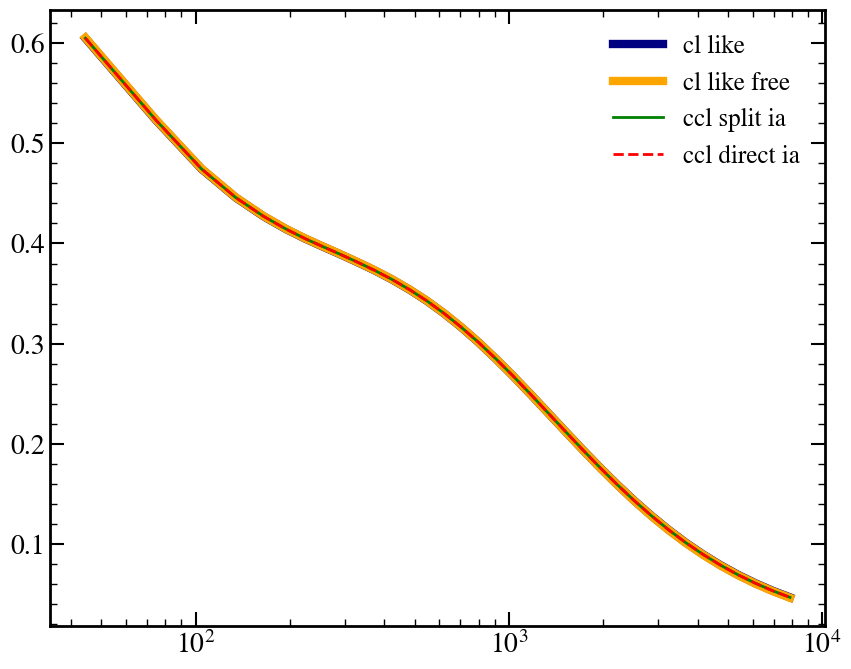

In [107]:
fig, ax = plt.subplots(1, 1, figsize=(10, 8))

ii = 0
bins = allbins[ii]
t1, t2 = bins['bins']

#####################################

# print(other_pk2d)
# pk2d_obj = other_pk2d
pk2d_obj = pk2d

clm = ll.cl_meta[0]

if myll.theory.sample_cen:
    ls = clm['l_eff']
elif myll.theory.sample_bpw:
    ls = myll.theory.l_sample
else:
    raise RuntimeError("Something went wrong with the sampling!")

# ccl_params = myll.theory.sampler_to_ccl_params(sampling_params)
# ccl_cosmo = ccl.Cosmology(**ccl_params, transfer_function=myll.theory.ccl_defaults['transfer_function'],
#                           matter_power_spectrum=myll.theory.ccl_defaults['matter_pk'],
#                           **myll.theory.ccl_arguments)
# # print(ccl_cosmo)
# # print(ccl_cosmo.compute_distances())
# # print(ccl_cosmo.compute_growth())
# print(ccl_cosmo.sigma8())
ccl_cosmo = model.theory['cl_like.CCL'].current_state['CCL']['cosmo']


# like in cl like free
ia_bias_1 = myll.theory._ia_bias(t1, sampling_params)
dndz = myll.theory._get_nz(t1, sampling_params)

ia_bias_2 = myll.theory._ia_bias(t2, sampling_params)
dndz = myll.theory._get_nz(t2, sampling_params)

tr1dir = ccl.WeakLensingTracer(ccl_cosmo, dndz=dndz, ia_bias=ia_bias_1, has_shear=True)
tr2dir = ccl.WeakLensingTracer(ccl_cosmo, dndz=dndz, ia_bias=ia_bias_2, has_shear=True)
print(tr1dir)
cl_direct = ccl.angular_cl(ccl_cosmo, tr1dir, tr2dir, ls,
                          limber_integration_method='spline',
                          p_of_k_a=pk2d_obj) * clm['pixbeam']
cl_direct = myll.theory._eval_interp_cl(cl_direct, clm['l_bpw'], clm['w_bpw'])


# like in cl like
dndz = model.theory['cl_like.Limber']._get_nz(ccl_cosmo, t1, **pars)
ia_bias_1 = dndz_cl_like = model.theory['cl_like.Limber']._get_ia_bias(ccl_cosmo, t1, **pars)
tr1 = ccl.WeakLensingTracer(ccl_cosmo, dndz=dndz)
tr1ia = ccl.WeakLensingTracer(ccl_cosmo, dndz=dndz, ia_bias=ia_bias_1, has_shear=False)
dndz = model.theory['cl_like.Limber']._get_nz(ccl_cosmo, t2, **pars)
ia_bias_2 = dndz_cl_like = model.theory['cl_like.Limber']._get_ia_bias(ccl_cosmo, t2, **pars)
tr2 = ccl.WeakLensingTracer(ccl_cosmo, dndz=dndz)
tr2ia = ccl.WeakLensingTracer(ccl_cosmo, dndz=dndz, ia_bias=ia_bias_2, has_shear=False)

cl_sh1_sh2 = ccl.angular_cl(ccl_cosmo, tr1, tr2, ls,
                            limber_integration_method='spline',
                            p_of_k_a=pk2d_obj) * clm['pixbeam']
cl_sh1_ia2 = ccl.angular_cl(ccl_cosmo, tr1, tr2ia, ls,
                            limber_integration_method='spline',
                            p_of_k_a=pk2d_obj) * clm['pixbeam']
cl_sh2_ia1 = ccl.angular_cl(ccl_cosmo, tr1ia, tr2, ls,
                            limber_integration_method='spline',
                            p_of_k_a=pk2d_obj) * clm['pixbeam']
cl_ia1_ia2 = ccl.angular_cl(ccl_cosmo, tr1ia, tr2ia, ls,
                            limber_integration_method='spline',
                            p_of_k_a=pk2d_obj) * clm['pixbeam']

A_IA_1 = sampling_params['ia_DESY3wl_A_IA']
A_IA_2 = sampling_params['ia_DESY3wl_A_IA']

cl_final = cl_sh1_sh2 + A_IA_2 * cl_sh1_ia2 + A_IA_1 * cl_sh2_ia1 + A_IA_1 * A_IA_2 * cl_ia1_ia2

cl_final = myll.theory._eval_interp_cl(cl_final, clm['l_bpw'], clm['w_bpw'])



#####################################

inds = ll.cl_meta[ii]['inds']

# data and model with scale cuts
datacol = 'r'
# modelcol = 'purple'
modelcol = 'navy'
mymodelcol = 'orange'

ell = ll.cl_meta[ii]['l_eff']
norm = ell*1e7

ax.semilogx(ell, norm * cls_th[inds], color=modelcol, lw=6, label='cl like')
ax.semilogx(ell, norm * theory_vector[f'{t1}_{t2}'], color=mymodelcol, lw=6, label='cl like free')
ax.semilogx(ell, norm * cl_final, color='green', lw=2, label='ccl split ia')
ax.semilogx(ell, norm * cl_direct, color='red', lw=2, ls='--', label='ccl direct ia')
ax.legend()

plt.show()

In [108]:
trs0 = {}
trs0_dnames = {}
trs1 = {}
trs1_dnames = {}
for name, q in model.theory['cl_like.Limber'].tracer_qs.items():
    if name == 'DESY3wl__0':
        print(q)
    if q == 'galaxy_density':
        dndz = model.theory['cl_like.Limber']._get_nz(ccl_cosmo, name, **pars)
        z = dndz[0]
        oz = np.ones_like(z)

        tr = ccl.NumberCountsTracer(ccl_cosmo, dndz=dndz, bias=(z, oz),
                                    has_rsd=False)
        # Tracer for the unbiased component
        t0 = None
        t0n = [None]
        if model.theory['cl_like.Limber'].bias_model in ['LagrangianPT', 'BaccoPT', 'BaccoHEFT', 'BaccoHEFT_lin']:
            t0 = tr
            t0n = ["m"]
        # Tracers for the biased components
        t1 = [tr]
        t1n = ['d1']
        if model.theory['cl_like.Limber'].is_PT_bias:
            for bn, dn in zip(['b2', 'bs', 'bk2'], ['d2', 's2', 'k2']):
                t1.append(tr)
                t1n.append(dn)
        # Magnification
        if model.theory['cl_like.Limber'].bin_properties[name]['mag_bias']:
            # We use s = 1/5 here so that (2-5s)=1 and we multiply by
            # (2-5s) in cl_total
            tr = ccl.NumberCountsTracer(ccl_cosmo, dndz=dndz,
                                        bias=(z, z*0), has_rsd=False,
                                        mag_bias=(z, oz/5.))
            t1.append(tr)
            t1n.append("w")
    elif q == 'galaxy_shear':
        dndz = model.theory['cl_like.Limber']._get_nz(ccl_cosmo, name, **pars)
        t0 = ccl.WeakLensingTracer(ccl_cosmo, dndz=dndz)
        print(t0)
        t0n = ["w"]
        if model.theory['cl_like.Limber'].ia_model == 'IANone':
            t1 = None
            t1n = [None]
        else:
            ia_bias = model.theory['cl_like.Limber']._get_ia_bias(ccl_cosmo, name, **pars)
            t1 = [ccl.WeakLensingTracer(ccl_cosmo, dndz=dndz,
                                        has_shear=False,
                                        ia_bias=ia_bias)]
            t1n = ['w']
    elif q == 'cmb_convergence':
        # B.H. TODO: pass z_source as parameter to the YAML file
        t0 = ccl.CMBLensingTracer(ccl_cosmo, z_source=1100)
        t0n = ['w']
        t1 = None
        t1n = [None]

    trs0[name] = t0
    trs1[name] = t1
    trs0_dnames[name] = t0n
    trs1_dnames[name] = t1n

print(trs0['DESY3wl__0'])

galaxy_shear
<pyccl.tracers.NzTracer>
	num       kernel             transfer       prefac  bessel 
	 0  0x4dc657a2cc94fd9e         None           2       -1   
<pyccl.tracers.NzTracer>
	num       kernel             transfer       prefac  bessel 
	 0  0xefe9a26d3575b792         None           2       -1   
<pyccl.tracers.NzTracer>
	num       kernel             transfer       prefac  bessel 
	 0  0x3b6e9629996fc143         None           2       -1   
<pyccl.tracers.NzTracer>
	num       kernel             transfer       prefac  bessel 
	 0  0xcad55978f637580d         None           2       -1   
<pyccl.tracers.NzTracer>
	num       kernel             transfer       prefac  bessel 
	 0  0x4dc657a2cc94fd9e         None           2       -1   


In [109]:
trs0, trs1, trs0_dnames, trs1_dnames = model.theory['cl_like.Limber']._get_tracers(ccl_cosmo, **pars)
for clm in model.theory['cl_like.Limber'].cl_meta:

    n1 = clm['bin_1']
    n2 = clm['bin_2']

    if (n1 != 'DESY3wl__0') or (n2 != 'DESY3wl__0'):
        continue
    print(n1, n2)


    t0_1 = trs0[n1]
    t0_2 = trs0[n2]
    t1_1 = trs1[n1]
    t1_2 = trs1[n2]
    # The unbiased tracers have only one element in the list "m" or
    # "w".
    t0dn_1 = trs0_dnames[n1][0]
    t0dn_2 = trs0_dnames[n2][0]
    t1dn_1 = trs1_dnames[n1]
    t1dn_2 = trs1_dnames[n2]
    # 00: unbiased x unbiased
    if t0_1 and t0_2:
        pk = pk2d
        cl00 = ccl.angular_cl(ccl_cosmo, t0_1, t0_2, ls,
                                limber_integration_method=model.theory['cl_like.Limber'].limber_integration_method,
                                p_of_k_a=pk) * clm['pixbeam']
    # 01: unbiased x biased
    if t0_1 and (t1_2 is not None):
        cl01 = []
        for t12, dn in zip(t1_2, t1dn_2):
            pk = pk2d
            if pk is not None:
                cl = ccl.angular_cl(ccl_cosmo, t0_1, t12, ls,
                                    limber_integration_method=model.theory['cl_like.Limber'].limber_integration_method,
                                    p_of_k_a=pk) * clm['pixbeam']
            else:
                cl = np.zeros_like(ls)
            cl01.append(cl)
        cl01 = np.array(cl01)

    # 10: biased x unbiased
    if n1 == n2:
        cl10 = cl01
    else:
        if t0_2 and (t1_1 is not None):
            cl10 = []
            for t11, dn in zip(t1_1, t1dn_1):
                pk = pk2d
                if pk is not None:
                    cl = ccl.angular_cl(ccl_cosmo, t11, t0_2, ls,
                                        limber_integration_method=model.theory['cl_like.Limber'].limber_integration_method,
                                        p_of_k_a=pk) * clm['pixbeam']
                else:
                    cl = np.zeros_like(ls)
                cl10.append(cl)
            cl10 = np.array(cl10)

    # 11: biased x biased
    if (t1_1 is not None) and (t1_2 is not None):
        cl11 = np.zeros([len(t1_1), len(t1_2), len(ls)])
        autocorr = n1 == n2
        for i1, (t11, dn1) in enumerate(zip(t1_1, t1dn_1)):
            for i2, (t12, dn2) in enumerate(zip(t1_2, t1dn_2)):
                if autocorr and i2 < i1:
                    cl11[i1, i2] = cl11[i2, i1]
                else:
                    pk = pk2d
                    if pk is not None:
                        cl = ccl.angular_cl(ccl_cosmo, t11, t12, ls,
                                            limber_integration_method=model.theory['cl_like.Limber'].limber_integration_method,
                                            p_of_k_a=pk) * clm['pixbeam']
                    else:
                        cl = np.zeros_like(ls)
                    cl11[i1, i2, :] = cl

print("cl00 / cl_sh1_sh2:", cl00 / cl_sh1_sh2)
print("cl01 / cl_sh1_ia2:", cl01 / cl_sh1_ia2)
print("cl10 / cl_sh2_ia1:", cl10 / cl_sh2_ia1)
print("cl11 / cl_ia1_ia2:", cl11 / cl_ia1_ia2)

DESY3wl__0 DESY3wl__0
cl00 / cl_sh1_sh2: [nan  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.]
cl01 / cl_sh1_ia2: [[nan  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
   1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
   1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
   1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
   1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
   1.  1.  1.  1.  1.  1.  1.  1.  1.  1.]]
cl10 / cl_sh2_ia1: [[nan  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.  1.
   1.  1.  1.  1.  1.  1. 

/tmp/ipykernel_1095474/1152920377.py:77: RuntimeWarning: invalid value encountered in divide
  print("cl00 / cl_sh1_sh2:", cl00 / cl_sh1_sh2)
/tmp/ipykernel_1095474/1152920377.py:78: RuntimeWarning: invalid value encountered in divide
  print("cl01 / cl_sh1_ia2:", cl01 / cl_sh1_ia2)
/tmp/ipykernel_1095474/1152920377.py:79: RuntimeWarning: invalid value encountered in divide
  print("cl10 / cl_sh2_ia1:", cl10 / cl_sh2_ia1)
/tmp/ipykernel_1095474/1152920377.py:80: RuntimeWarning: invalid value encountered in divide
  print("cl11 / cl_ia1_ia2:", cl11 / cl_ia1_ia2)


In [110]:
cld = model.theory['cl_like.Limber'].current_state['Limber']['cl_data']

# Construct bias vector
bias_vec = np.zeros(len(model.theory['cl_like.ClFinal'].bias_names))
for i, k in enumerate(model.theory['cl_like.ClFinal'].bias_names):
    if k[-2:] == "_s":
        # Magnification i.e. (2 - 5s)
        bias_vec[i] = 2 - 5*pars[k]
    else:
        bias_vec[i] = pars[k]

# Construct global bias vector
global_bias = model.theory['cl_like.ClFinal']._get_global_bias(**pars)

print(sampling_params['ia_DESY3wl_A_IA'])

for icl, clm in enumerate(model.theory['cl_like.ClFinal'].cl_meta):
    cl_this = np.zeros_like(clm['l_eff'])
    n1 = clm['bin_1']
    n2 = clm['bin_2']
    if not (n1=='DESY3wl__0' and n2=='DESY3wl__0'):
        continue
    e1 = model.theory['cl_like.ClFinal'].bias_info[n1]['eps']
    e2 = model.theory['cl_like.ClFinal'].bias_info[n2]['eps']
    ind1 = model.theory['cl_like.ClFinal'].bias_info[n1]['bias_ind']
    ind2 = model.theory['cl_like.ClFinal'].bias_info[n2]['bias_ind']
    b1 = bias_vec[ind1] if ind1 is not None else None
    b2 = bias_vec[ind2] if ind2 is not None else None
    print(e1, e1)
    print(b1, b2)
    inds = clm['inds']
    if e1 and e2:
        cl_this += cld['cl00'][icl]
    if e1 and (b2 is not None):
        cl_this += np.dot(b2, cld['cl01'][icl]) # (nbias) , (nbias, nell)
    if e2 and (b1 is not None):
        cl_this += np.dot(b1, cld['cl10'][icl]) # (nbias) , (nbias, nell)
    if (b1 is not None) and (b2 is not None):
        cl_this += np.dot(b1, np.dot(b2, cld['cl11'][icl])) # (nbias1) * ((nbias2), (nbias1,nbias2,nell))

    print(global_bias[n1], global_bias[n2])
    # Multiply global biases (e.g. multiplicative bias)
    cl_this *= global_bias[n1]
    cl_this *= global_bias[n2]


    mycl00 = myll.theory._eval_interp_cl(cl_sh1_sh2, clm['l_bpw'], clm['w_bpw'])
    mycl01 = myll.theory._eval_interp_cl(cl_sh1_ia2, clm['l_bpw'], clm['w_bpw'])
    mycl10 = myll.theory._eval_interp_cl(cl_sh2_ia1, clm['l_bpw'], clm['w_bpw'])
    mycl11 = myll.theory._eval_interp_cl(cl_ia1_ia2, clm['l_bpw'], clm['w_bpw'])


    print(cld['cl00'][icl] / mycl00)
    print(cld['cl01'][icl] / mycl01)
    print(cld['cl10'][icl] / mycl10)
    print(cld['cl11'][icl] / mycl11)
    print(cl_this / cl_final)
    A_IA_1 = A_IA_2 = 0.13975294
    print(cl_this / (mycl00 + A_IA_2 * mycl01 + A_IA_1 * mycl10 + A_IA_1 * A_IA_2 * mycl11))

0.139753
True True
[0.13975294] [0.13975294]
1.0 1.0
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
[[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
  1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]
[[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
  1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]
[[[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
   1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]]
[1.00000004 1.00000004 1.00000004 1.00000004 1.00000004 1.00000004
 1.00000004 1.00000004 1.00000004 1.00000004 1.00000004 1.00000004
 1.00000004 1.00000004 1.00000004 1.00000004 1.00000004 1.00000004
 1.00000004 1.00000005 1.00000005 1.00000005 1.00000005 1.00000005
 1.00000005 1.00000005 1.00000005 1.00000005 1.00000005 1.00000005
 1.00000005 1.00000005 1.00000005 1.00000005 1.00000005]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


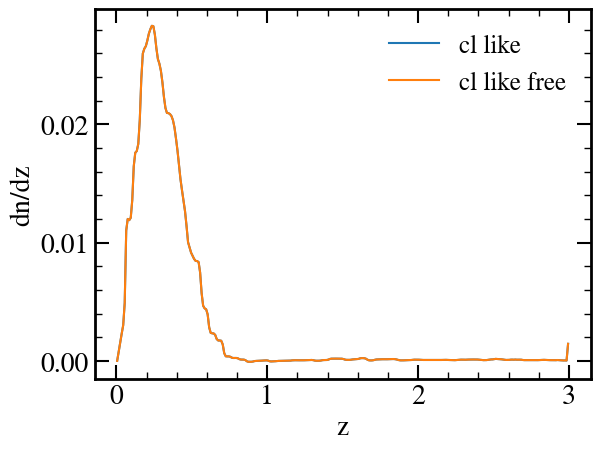

In [113]:
dndz_cl_like = model.theory['cl_like.Limber']._get_nz(ccl_cosmo, 'DESY3wl__0', **pars)
dndz = myll.theory._get_nz('DESY3wl__0', sampling_params)
plt.plot(dndz_cl_like[0], dndz_cl_like[1], label='cl like')
plt.plot(dndz[0], dndz[1], label='cl like free')
plt.xlabel('z')
plt.ylabel('dn/dz')
plt.legend()
plt.show()